# HealthEquity Agent: dataset exploration and patient-level splitting

This notebook documents initial exploration of the UCI Diabetes 130-US Hospitals (1999-2008) dataset and prepares a patient-level split for the 30-day readmission baseline. Each row represents a hospital stay, not a unique patient.

## Notebook guide

1. Set up the environment and load the original dataset.
2. Inspect structure, missing values, duplicates, repeated patients, and target balance.
3. Explore numerical distributions and potential outliers.
4. Review demographics, categorical codes, diagnoses, medications, and laboratory categories.
5. Define the modeling cohort, split by patient, verify separation, and export the partitions.
6. Review the independent synthetic Fairlearn demonstration in the appendix.

## How to run

Use the project's .venv kernel and run cells from top to bottom. Start from the repository root or its notebooks directory. The source file must exist at data/diabetic_data.csv. The export cell writes or refreshes the three CSV files in data/splits; the source CSV remains unchanged.

## Data boundaries

- df is the source dataset; df_work is the exploratory copy without weight and with a derived target.
- df_model applies the recorded-death exclusion rule before patient-level splitting.
- train_df, val_df, and test_df are distinct patient partitions.
- Full-dataset work here is descriptive. Continue relationship analysis, feature selection, and learned preprocessing on Train in notebooks/model_development.ipynb.
- Validation supports model and threshold selection; Test is reserved for final evaluation.
- No predictive model is trained and no LLM API is called in this notebook.

Source and variable definitions: [UCI dataset documentation](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008).

## 1. Environment and data loading

### Import analysis libraries

Load pandas for tables, matplotlib and seaborn for plots, and GroupShuffleSplit for patient-level partitions. MetricFrame and accuracy_score are used only in the independent synthetic appendix.

In [46]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from fairlearn.metrics import MetricFrame
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GroupShuffleSplit

### Resolve the project directory and import shared helpers

If the kernel starts in notebooks, move to the repository root. Import the tested loader and target-creation helper from app.data instead of duplicating their implementations.

In [2]:
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
from app.data import create_target, load_data

### Load the source dataset

Use a relative path to data/diabetic_data.csv. The loader treats ? as missing and preserves the literal category None. Keep the original table in df; subsequent exploration uses a separate working copy.

In [3]:
data_path = Path("data/diabetic_data.csv")
if not data_path.exists():
    data_path = Path("../data/diabetic_data.csv")

df = load_data(data_path)

## 2. Dataset structure and data quality

### Preview the table

Inspect a few rows to understand the layout and recorded values. This preview is local only; patient rows and identifiers must not be sent to an LLM or included in public screenshots.

In [4]:

df.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


### Check dataset dimensions

shape reports (rows, columns). The original table contains 101,766 hospital stays and 50 columns.

In [5]:
df.shape


(101766, 50)

### Inspect column names

Review the available fields before selecting features. Identifiers and numeric category codes must not be confused with quantitative measurements.

In [6]:
df.columns.tolist()

['encounter_id',
 'patient_nbr',
 'race',
 'gender',
 'age',
 'weight',
 'admission_type_id',
 'discharge_disposition_id',
 'admission_source_id',
 'time_in_hospital',
 'payer_code',
 'medical_specialty',
 'num_lab_procedures',
 'num_procedures',
 'num_medications',
 'number_outpatient',
 'number_emergency',
 'number_inpatient',
 'diag_1',
 'diag_2',
 'diag_3',
 'number_diagnoses',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted']

### Count distinct patients

Compare unique patient_nbr values with the row count. Patients can have multiple stays, which motivates patient-level rather than row-level splitting.

In [7]:
df['patient_nbr'].nunique()

71518

### Review types and memory usage

The compact info summary gives an initial view of storage types and dataset size. The next cell explicitly includes observed counts for every column.

In [8]:
df.info(
    
)

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

### Inspect non-missing counts

Display full column information to inspect types and explicit missingness. Encoded unknown categories and literal None strings are not counted as pandas missing values.

In [9]:
df.info(verbose=True, show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

### Measure explicit missingness

Compute missing-value percentages and display affected columns. These percentages capture ? markers handled by the loader, but not unknown information stored as numeric codes or the not-performed laboratory category.

In [10]:
missing_pct = df.isna().mean() * 100
missing_pct[missing_pct > 0].sort_values(ascending=False).round(2)

weight               96.86
medical_specialty    49.08
payer_code           39.56
race                  2.23
diag_3                1.40
diag_2                0.35
diag_1                0.02
dtype: float64

### Create the exploratory working copy

Drop weight from df_work because 96.86% of its values are missing. copy keeps exploratory changes separate from df. No rows are removed here.

In [11]:
df_work = df.drop(columns=["weight"]).copy()

print("Original:", df.shape)
print("Working copy:", df_work.shape)

Original: (101766, 50)
Working copy: (101766, 49)


### Check duplicate records and encounter IDs

Count exact duplicate rows and repeated encounter identifiers separately. Repeated patient IDs are expected and are not automatically duplicate records.

In [12]:
print("Duplicate rows:", df_work.duplicated().sum())
print("Duplicate encounter IDs:", df_work["encounter_id"].duplicated().sum())

Duplicate rows: 0
Duplicate encounter IDs: 0


### Quantify repeated hospital stays

Count patients with multiple stays and the maximum stays for one patient. All encounters from a patient must remain within one split.

In [14]:
visits_per_patient = df_work["patient_nbr"].value_counts()

print("Patients with multiple stays:", (visits_per_patient > 1).sum())
print("Maximum stays for one patient:", visits_per_patient.max())

Patients with multiple stays: 16773
Maximum stays for one patient: 40


### Inspect readmission categories

Display counts and percentages for NO, >30, and <30 before creating the binary target. This reveals class imbalance.

In [13]:
counts = df_work["readmitted"].value_counts(dropna=False)

pd.DataFrame({
    "count": counts,
    "percent": (counts / len(df_work) * 100).round(2)
})

,count,percent
readmitted,,
NO,54864,53.91
>30,35545,34.93
<30,11357,11.16


### Create the binary target

Use the shared helper to assign 1 to <30 and 0 to NO or >30. Expected exploratory counts are 11,357 positive and 90,409 negative stays. Neither readmitted nor target may be included among the predictors for this outcome.

In [18]:
df_work["target"] = create_target(df_work)
df_work["target"].value_counts()

target
0    90409
1    11357
Name: count, dtype: int64

## 3. Numerical feature exploration

### Summarize quantitative features

Select eight meaningful measurements and counts, excluding IDs and category codes. describe().T gives descriptive statistics; add sample variance, range, and IQR (Q3 minus Q1).

In [17]:
numeric_cols = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses"
]

summary = df_work[numeric_cols].describe().T

summary["variance"] = df_work[numeric_cols].var()
summary["range"] = summary["max"] - summary["min"]
summary["IQR"] = summary["75%"] - summary["25%"]

summary.round(2)

,count,mean,std,min,25%,50%,75%,max,variance,range,IQR
time_in_hospital,101766.0,4.40,2.99,1.0,2.0,4.0,6.0,14.0,8.91,13.0,4.0
num_lab_procedures,101766.0,43.10,19.67,1.0,31.0,44.0,57.0,132.0,387.08,131.0,26.0
num_procedures,101766.0,1.34,1.71,0.0,0.0,1.0,2.0,6.0,2.91,6.0,2.0
num_medications,101766.0,16.02,8.13,1.0,10.0,15.0,20.0,81.0,66.06,80.0,10.0
number_outpatient,101766.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0,1.61,42.0,0.0
number_emergency,101766.0,0.20,0.93,0.0,0.0,0.0,0.0,76.0,0.87,76.0,0.0
number_inpatient,101766.0,0.64,1.26,0.0,0.0,0.0,1.0,21.0,1.59,21.0,1.0
number_diagnoses,101766.0,7.42,1.93,1.0,6.0,8.0,9.0,16.0,3.74,15.0,3.0


### Plot histograms and boxplots

Each feature has a histogram with KDE on the left and a boxplot on the right. Counts are discrete; KDE is a smoothed visual aid, not an assumption of a continuous or normal distribution. Boxplot flags are prompts for review, not automatic deletion rules.

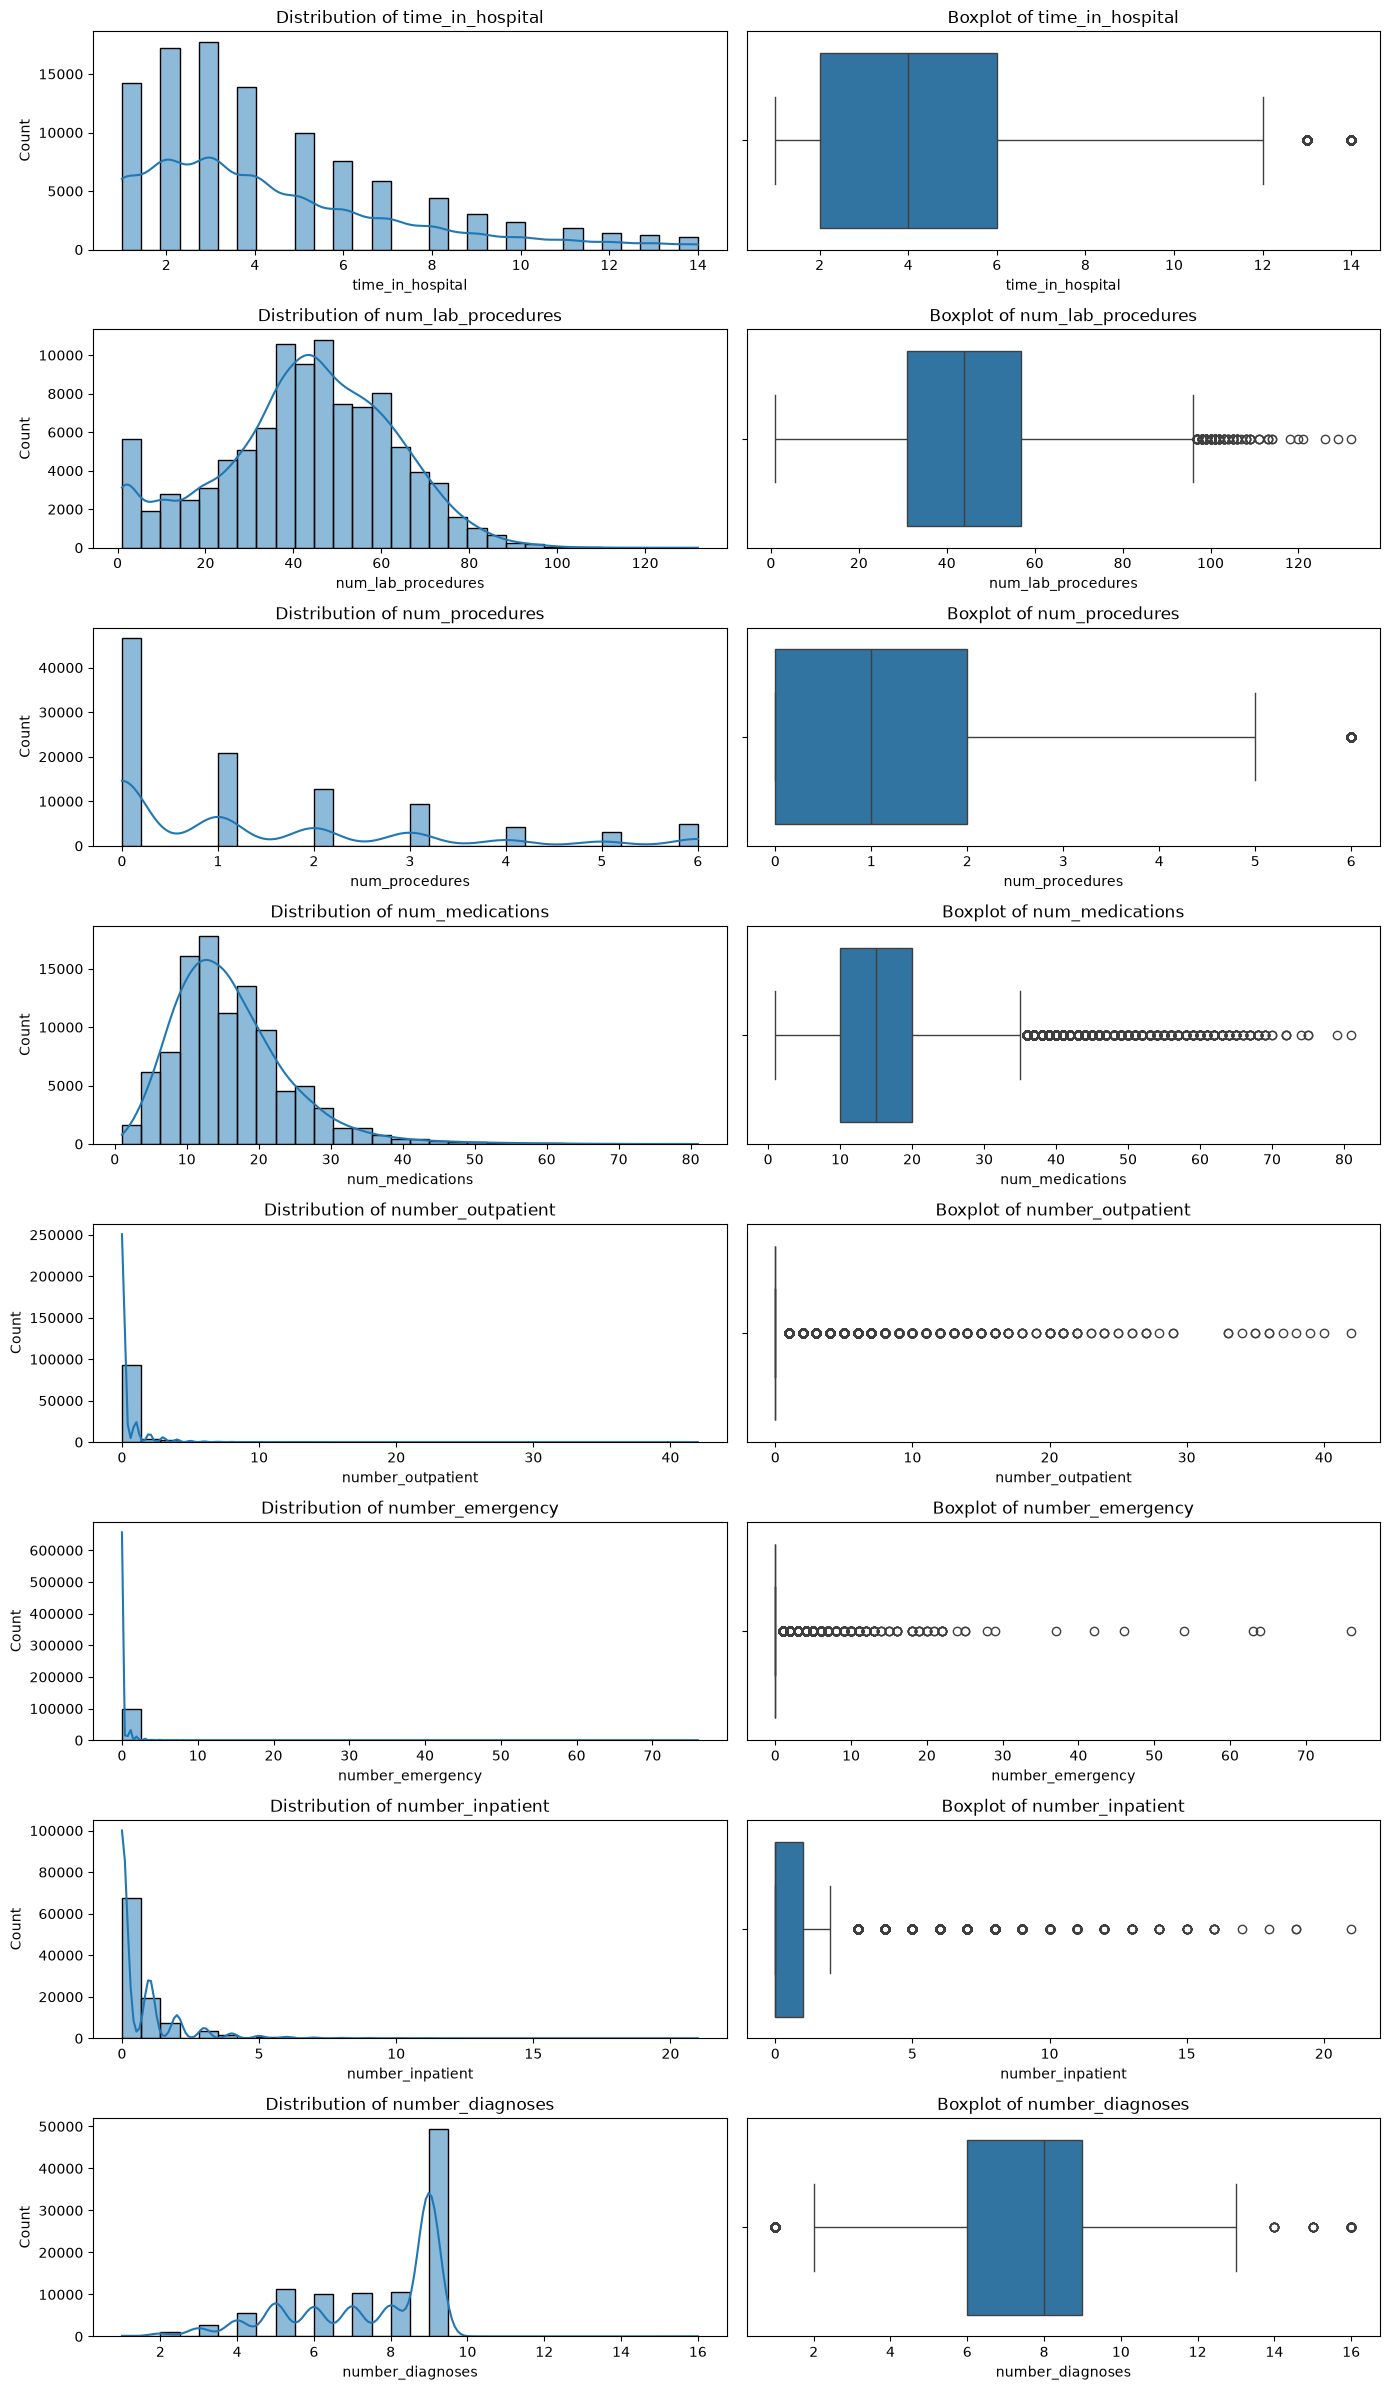

In [31]:
fig, axes = plt.subplots(
    len(numeric_cols), 2,
    figsize=(14, 3 * len(numeric_cols)),
)

for i, column in enumerate(numeric_cols):
    sns.histplot(
        data=df_work,
        x=column,
        bins=30,
        kde=True,
        ax=axes[i, 0],kde_kws={"bw_adjust": 1.5},
    )
    axes[i, 0].set_title(f"Distribution of {column}")

    sns.boxplot(
        data=df_work,
        x=column,
        ax=axes[i, 1],
    )
    axes[i, 1].set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()

## Numerical feature observations

- **time_in_hospital:** Right-skewed, with a median of 4 days. The middle 50% of stays fall between 2 and 6 days. Values of 13–14 days exceed the upper IQR fence but are retained.

- **num_lab_procedures:** Broadly distributed and closer to symmetric than most other numerical features, with slight negative skew. The median is 44, and the maximum is 132.

- **num_procedures:** Right-skewed, with 45.84% of stays recording zero procedures. Values range from 0 to 6.

- **num_medications:** Right-skewed, with a median of 15. The middle 50% fall between 10 and 20, with a maximum of 81.

- **number_outpatient:** Highly right-skewed; 83.55% of values are zero. The maximum is 42.

- **number_emergency:** Highly right-skewed; 88.81% of values are zero. The maximum is 76.

- **number_inpatient:** Right-skewed; 66.46% of values are zero. The maximum is 21.

- **number_diagnoses:** Negatively skewed, with a median of 8. The middle 50% fall between 6 and 9, with values ranging from 1 to 16.

### Outlier handling

- For number_outpatient and number_emergency, Q1 and Q3 are both zero, so the IQR is zero. Consequently, all positive values appear as outliers under the standard boxplot rule.
- Statistical outliers do not necessarily indicate data errors.
- No values are removed or capped at this stage. Unusual values require further investigation before any treatment.

## 4. Categorical features and demographic representation

### Identify text and categorical columns

Select columns by storage type. This exploration list includes readmitted and excludes numeric-coded categories reviewed later; it is not the final model feature list.

In [33]:
categorical_cols = df_work.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()

categorical_cols

['race',
 'gender',
 'age',
 'payer_code',
 'medical_specialty',
 'diag_1',
 'diag_2',
 'diag_3',
 'max_glu_serum',
 'A1Cresult',
 'metformin',
 'repaglinide',
 'nateglinide',
 'chlorpropamide',
 'glimepiride',
 'acetohexamide',
 'glipizide',
 'glyburide',
 'tolbutamide',
 'pioglitazone',
 'rosiglitazone',
 'acarbose',
 'miglitol',
 'troglitazone',
 'tolazamide',
 'examide',
 'citoglipton',
 'insulin',
 'glyburide-metformin',
 'glipizide-metformin',
 'glimepiride-pioglitazone',
 'metformin-rosiglitazone',
 'metformin-pioglitazone',
 'change',
 'diabetesMed',
 'readmitted']

### Count distinct categories

nunique excludes missing values by default. Use the result to distinguish constant, low-cardinality, and high-cardinality features.

In [34]:
df_work[categorical_cols].nunique().sort_values()

examide                       1
citoglipton                   1
acetohexamide                 2
metformin-rosiglitazone       2
troglitazone                  2
tolbutamide                   2
glimepiride-pioglitazone      2
glipizide-metformin           2
change                        2
diabetesMed                   2
metformin-pioglitazone        2
tolazamide                    3
readmitted                    3
gender                        3
nateglinide                   4
chlorpropamide                4
miglitol                      4
acarbose                      4
rosiglitazone                 4
pioglitazone                  4
glipizide                     4
glyburide                     4
insulin                       4
glimepiride                   4
glyburide-metformin           4
metformin                     4
max_glu_serum                 4
repaglinide                   4
A1Cresult                     4
race                          5
age                          10
payer_co

### Count gender and race categories

Include missing values explicitly so incomplete demographic records remain visible. Counts refer to hospital stays, not unique patients.

In [15]:
print("Gender:")
print(df_work["gender"].value_counts(dropna=False))

print("\nRace:")
print(df_work["race"].value_counts(dropna=False))

Gender:
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64

Race:
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64


### Visualize demographic representation

Plot hospital-stay counts by gender and race. fillna("Missing") changes chart labels only, not the dataset. For general use, missing labels must remain distinguishable from an existing literal category named Missing.

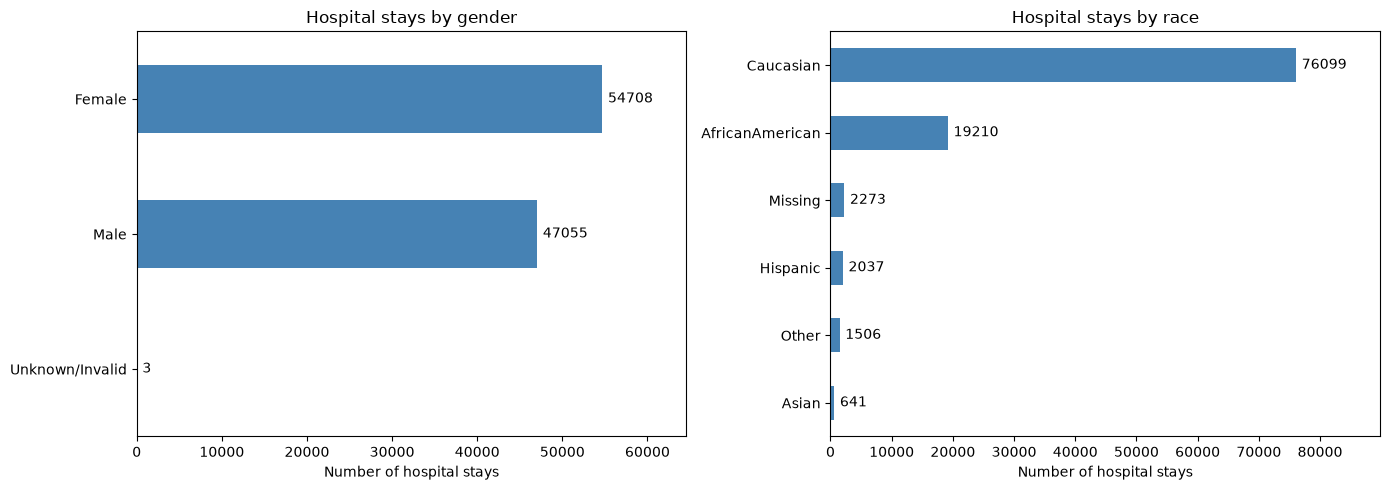

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column in zip(axes, ["gender", "race"]):
    counts = df_work[column].fillna("Missing").value_counts()
    counts.plot.barh(ax=ax, color="#4682B4")

    ax.invert_yaxis()
    ax.set_title(f"Hospital stays by {column}")
    ax.set_xlabel("Number of hospital stays")
    ax.set_ylabel("")
    ax.bar_label(ax.containers[0], fmt="%.0f", padding=4)
    ax.set_xlim(0, counts.max() * 1.18)

plt.tight_layout()
plt.show()

### Inspect constant medications and unknown gender

Check exact counts for examide, citoglipton, and the Unknown/Invalid gender category. A small group cannot support the same reporting as a large group.

In [35]:
for column in ["examide", "citoglipton", "gender"]:
    print(f"\n{column}:")
    print(df_work[column].value_counts(dropna=False))


examide:
examide
No    101766
Name: count, dtype: int64

citoglipton:
citoglipton
No    101766
Name: count, dtype: int64

gender:
gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64


## Constant columns and gender categories

- **examide** and **citoglipton:** Both columns contain only "No" across all 101,766 hospital stays. They provide no variation and will be excluded from model features. The original dataset remains unchanged.

- **gender:** The dataset contains 54,708 Female, 47,055 Male, and 3 Unknown/Invalid records. Unknown/Invalid records are retained as a separate category at this stage. Their group-level fairness results will be suppressed because the group is below the minimum reporting threshold.

### Inspect age, race, and payer categories

Display all observed categories and missing values. Age bands are already discrete intervals. Verify payer-code meanings before interpretation; do not infer socioeconomic status from unexplained codes.

In [36]:
for column in ["age", "race", "payer_code"]:
    print(f"\n{column}:")
    print(df_work[column].value_counts(dropna=False))


age:
age
[70-80)     26068
[60-70)     22483
[50-60)     17256
[80-90)     17197
[40-50)      9685
[30-40)      3775
[90-100)     2793
[20-30)      1657
[10-20)       691
[0-10)        161
Name: count, dtype: int64

race:
race
Caucasian          76099
AfricanAmerican    19210
NaN                 2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64

payer_code:
payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64


## Age, race, and payer code observations

All counts represent hospital stays, not unique patients.

- **age:** Recorded in 10-year intervals. The largest group is [70-80), with 26,068 stays. Older age groups are more heavily represented. Existing age bands are retained.

- **race:** Group sizes are unequal. Caucasian is the largest group (76,099 stays), followed by AfricanAmerican (19,210). Race is missing for 2,273 stays (2.23%). Missing values are retained and will be reported as a separate group.

- **payer_code:** Missing for 40,256 stays (39.56%). This limits the interpretation of comparisons by payer category. Code meanings must be verified before interpretation. The FR category contains only one stay and will be suppressed in group-level fairness reporting.

- No rows or categories are removed at this stage. Reporting eligibility will depend on both group size and positive-outcome counts.

## 5. Coded and high-cardinality features

### Review admission and discharge codes

Sort frequencies by ID to compare with data/IDS_mapping.csv. These values are categorical labels, not numerical quantities. Note encoded unknowns and death-related categories before cohort definition.

In [37]:
for column in [
    "admission_type_id",
    "discharge_disposition_id",
    "admission_source_id",
]:
    print(f"\n{column}:")
    print(df_work[column].value_counts(dropna=False).sort_index())


admission_type_id:
admission_type_id
1    53990
2    18480
3    18869
4       10
5     4785
6     5291
7       21
8      320
Name: count, dtype: int64

discharge_disposition_id:
discharge_disposition_id
1     60234
2      2128
3     13954
4       815
5      1184
6     12902
7       623
8       108
9        21
10        6
11     1642
12        3
13      399
14      372
15       63
16       11
17       14
18     3691
19        8
20        2
22     1993
23      412
24       48
25      989
27        5
28      139
Name: count, dtype: int64

admission_source_id:
admission_source_id
1     29565
2      1104
3       187
4      3187
5       855
6      2264
7     57494
8        16
9       125
10        8
11        2
13        1
14        2
17     6781
20      161
22       12
25        2
Name: count, dtype: int64


## Admission and discharge code observations

- admission_type_id, discharge_disposition_id, and admission_source_id contain categorical codes, not numerical quantities.

- The most common admission type is Emergency (code 1; 53,990 stays).

- The most common discharge disposition is Discharged to home (code 1; 60,234 stays).

- The most common admission source is Emergency Room (code 7; 57,494 stays).

- Some unavailable or unmapped values are represented by numeric codes rather than NaN. Standard missing-value checks do not capture these categories. Their treatment must be documented during preprocessing.

- Discharge code 11 means Expired and occurs in 1,642 stays. Eligibility rules for the readmission cohort must be defined before training, including how to handle death-related discharge categories.

- Original codes and all rows are retained at this exploratory stage.

### Inspect specialties and diagnosis codes

Report distinct non-missing values, missingness, and the ten most frequent categories. Diagnosis codes remain strings; grouping requires a verified mapping. Learn rare-category handling from Train only.

In [38]:
for column in ["medical_specialty", "diag_1", "diag_2", "diag_3"]:
    print(f"\n{column}")
    print("Unique values:", df_work[column].nunique())
    print("Missing %:", round(df_work[column].isna().mean() * 100, 2))
    print(df_work[column].value_counts(dropna=False).head(10))


medical_specialty
Unique values: 72
Missing %: 49.08
medical_specialty
NaN                           49949
InternalMedicine              14635
Emergency/Trauma               7565
Family/GeneralPractice         7440
Cardiology                     5352
Surgery-General                3099
Nephrology                     1613
Orthopedics                    1400
Orthopedics-Reconstructive     1233
Radiologist                    1140
Name: count, dtype: int64

diag_1
Unique values: 716
Missing %: 0.02
diag_1
428    6862
414    6581
786    4016
410    3614
486    3508
427    2766
491    2275
715    2151
682    2042
434    2028
Name: count, dtype: int64

diag_2
Unique values: 748
Missing %: 0.35
diag_2
276    6752
428    6662
250    6071
427    5036
401    3736
496    3305
599    3288
403    2823
414    2650
411    2566
Name: count, dtype: int64

diag_3
Unique values: 789
Missing %: 1.4
diag_3
250    11555
401     8289
276     5175
428     4577
427     3955
414     3664
496     2605
403     23

## High-cardinality categorical features

- **medical_specialty:** Contains 72 distinct non-missing categories. Values are missing for 49,949 stays (49.08%). InternalMedicine is the most common recorded specialty, followed by Emergency/Trauma and Family/GeneralPractice. The column is retained for now; missing-value treatment and model inclusion will be decided during training preparation.

- **diag_1:** Contains 716 distinct non-missing codes, with 0.02% missing values.
- **diag_2:** Contains 748 distinct non-missing codes, with 0.35% missing values.
- **diag_3:** Contains 789 distinct non-missing codes, with 1.40% missing values.

- Diagnosis codes are categorical identifiers and must remain strings. Their numeric appearance does not imply a numerical scale.
- Any grouping of diagnosis codes requires a verified mapping.
- Rare-category handling must be learned from the training split only.
- No columns, categories, or rows are removed at this stage.

## 6. Medications and laboratory test categories

### Compare category percentages

Each summary row represents a feature and each column a category. Include missing values in the denominator. fillna(0) fills absent combinations in this summary only. Two-decimal rounding can hide rare categories.

In [39]:
medication_cols = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "examide",
    "citoglipton", "insulin", "glyburide-metformin",
    "glipizide-metformin", "glimepiride-pioglitazone",
    "metformin-rosiglitazone", "metformin-pioglitazone",
]

columns_to_check = medication_cols + [
    "change", "diabetesMed", "max_glu_serum", "A1Cresult",
]

category_percentages = pd.DataFrame({
    column: df_work[column].value_counts(
        normalize=True, dropna=False
    ) * 100
    for column in columns_to_check
}).T.fillna(0)

category_percentages.round(2)

,>200,>300,>7,>8,Ch,Down,No,None,Norm,Steady,Up,Yes
metformin,0.00,0.00,0.00,0.00,0.0,0.57,80.36,0.00,0.00,18.03,1.05,0.0
repaglinide,0.00,0.00,0.00,0.00,0.0,0.04,98.49,0.00,0.00,1.36,0.11,0.0
nateglinide,0.00,0.00,0.00,0.00,0.0,0.01,99.31,0.00,0.00,0.66,0.02,0.0
chlorpropamide,0.00,0.00,0.00,0.00,0.0,0.00,99.92,0.00,0.00,0.08,0.01,0.0
glimepiride,0.00,0.00,0.00,0.00,0.0,0.19,94.90,0.00,0.00,4.59,0.32,0.0
acetohexamide,0.00,0.00,0.00,0.00,0.0,0.00,100.00,0.00,0.00,0.00,0.00,0.0
glipizide,0.00,0.00,0.00,0.00,0.0,0.55,87.53,0.00,0.00,11.16,0.76,0.0
glyburide,0.00,0.00,0.00,0.00,0.0,0.55,89.53,0.00,0.00,9.11,0.80,0.0
tolbutamide,0.00,0.00,0.00,0.00,0.0,0.00,99.98,0.00,0.00,0.02,0.00,0.0
pioglitazone,0.00,0.00,0.00,0.00,0.0,0.12,92.80,0.00,0.00,6.85,0.23,0.0


### Inspect near-constant medication columns

Flag columns where one category represents at least 99% of stays, then display exact counts. This distinguishes constant from near-constant features. The cell does not remove columns.

In [40]:
rare_medication_cols = [
    column
    for column in medication_cols
    if df_work[column].value_counts(normalize=True).max() >= 0.99
]

for column in rare_medication_cols:
    print(f"\n{column}:")
    print(df_work[column].value_counts(dropna=False))


nateglinide:
nateglinide
No        101063
Steady       668
Up            24
Down          11
Name: count, dtype: int64

chlorpropamide:
chlorpropamide
No        101680
Steady        79
Up             6
Down           1
Name: count, dtype: int64

acetohexamide:
acetohexamide
No        101765
Steady         1
Name: count, dtype: int64

tolbutamide:
tolbutamide
No        101743
Steady        23
Name: count, dtype: int64

acarbose:
acarbose
No        101458
Steady       295
Up            10
Down           3
Name: count, dtype: int64

miglitol:
miglitol
No        101728
Steady        31
Down           5
Up             2
Name: count, dtype: int64

troglitazone:
troglitazone
No        101763
Steady         3
Name: count, dtype: int64

tolazamide:
tolazamide
No        101727
Steady        38
Up             1
Name: count, dtype: int64

examide:
examide
No    101766
Name: count, dtype: int64

citoglipton:
citoglipton
No    101766
Name: count, dtype: int64

glyburide-metformin:
glyburide-metform

## Rare medication categories

- examide and citoglipton are constant: all 101,766 values are "No".
- Several other medication columns are near-constant, with "No" representing at least 99% of stays.
- acetohexamide, glimepiride-pioglitazone, and metformin-pioglitazone each have only one "Steady" record. metformin-rosiglitazone has two, and troglitazone has three.
- Rounded percentages can display 100.00% even when a rare alternative category exists.
- Near-constant features are retained at this stage. Feature selection and rare-category handling will be determined using the training split only.

## Laboratory test categories

- "None" in max_glu_serum and A1Cresult means the test was not performed, according to the UCI dataset documentation.
- This category represents 94.75% and 83.28% of stays, respectively.
- "None" is retained as a separate category and is not treated as a normal test result or silently converted to NaN.
- Neither column is dropped solely because the test-not-performed category is frequent.

## 7. Modeling cohort

### Exclude recorded death-related discharges

For predictions at discharge, form df_model by excluding codes 11, 19, 20, and 21. This is an eligibility rule, not outlier handling. Preserve df and df_work; unknown dispositions do not confirm survival.

In [42]:
death_discharge_codes = [11, 19, 20, 21]
df_model = df_work.loc[
    ~df_work["discharge_disposition_id"].isin(death_discharge_codes)
].copy()

print("Before:", len(df_work))
print("After:", len(df_model))
print("Excluded:", len(df_work) - len(df_model))

Before: 101766
After: 100114
Excluded: 1652


## Modeling cohort

- Predictions are intended to be made at hospital discharge.
- Stays with death-related discharge codes 11, 19, 20, and 21 are excluded before splitting.
- This excludes 1,652 stays, leaving 100,114 stays in the modeling cohort.
- Hospice categories are not automatically treated as deaths.
- The original dataset and exploratory working copy remain unchanged.
- Unknown or unmapped discharge dispositions remain included; absence of a death code does not confirm survival.

## 8. Patient-level splitting and export

### Create Train, Validation, and Test partitions

Allocate approximately 70% of patient groups to Train. Split the remaining 30% equally into Validation and Test. random_state=42 makes this reproducible for the same ordered dataset. Group proportions do not guarantee exact row proportions or target stratification.

In [ ]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42,
)

train_idx, remaining_idx = next(
    splitter.split(df_model, groups=df_model["patient_nbr"])
)

train_df = df_model.iloc[train_idx].copy()
remaining_df = df_model.iloc[remaining_idx].copy()

splitter_remaining = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42,
)

val_idx, test_idx = next(
    splitter_remaining.split(
        remaining_df,
        groups=remaining_df["patient_nbr"],
    )
)

val_df = remaining_df.iloc[val_idx].copy()
test_df = remaining_df.iloc[test_idx].copy()

### Review split sizes and outcome balance

Report stays, distinct patients, and positive outcome percentages. Similar prevalence is descriptive; do not repeatedly optimize the split against Test.

In [45]:
for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df),
]:
    print(
        name,
        "| Stays:", len(data),
        "| Patients:", data["patient_nbr"].nunique(),
        "| Positive %:", round(data["target"].mean() * 100, 2),
    )

Train | Stays: 69944 | Patients: 49307 | Positive %: 11.3
Validation | Stays: 15172 | Patients: 10566 | Positive %: 11.52
Test | Stays: 14998 | Patients: 10566 | Positive %: 11.35


### Verify patient separation and row coverage

Construct patient-ID sets and require pairwise intersections to be empty. Assertions also require the partition row counts to sum to the modeling cohort size. A failure must be resolved before training.

In [47]:
train_patients = set(train_df["patient_nbr"])
val_patients = set(val_df["patient_nbr"])
test_patients = set(test_df["patient_nbr"])

print("Train ∩ Validation:", len(train_patients & val_patients))
print("Train ∩ Test:", len(train_patients & test_patients))
print("Validation ∩ Test:", len(val_patients & test_patients))

assert train_patients.isdisjoint(val_patients)
assert train_patients.isdisjoint(test_patients)
assert val_patients.isdisjoint(test_patients)

assert len(train_df) + len(val_df) + len(test_df) == len(df_model)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


## Patient-level data splitting

- The modeling cohort contains 100,114 hospital stays after excluding 1,652 stays with death-related discharge codes.
- Data was split using GroupShuffleSplit with random_state=42.
- Approximately 70% of patients were assigned to training, 15% to validation, and 15% to testing.
- All stays belonging to the same patient were kept in one split.

| Split | Hospital stays | Unique patients | Positive outcome rate |
|---|---:|---:|---:|
| Train | 69,944 | 49,307 | 11.30% |
| Validation | 15,172 | 10,566 | 11.52% |
| Test | 14,998 | 10,566 | 11.35% |

### Split verification

- No patient overlap was found between any pair of splits.
- The combined row count equals the modeling cohort size.
- Positive outcome rates are similar across splits. The splitting method is group-based, not explicitly stratified by outcome.

### Next steps

- Further relationship analysis and preprocessing decisions will use the training split only.
- Validation data will be used for model and operating-threshold selection.
- Test data will remain reserved for final evaluation.
- Further analysis will continue in a separate model development notebook.

### Export the three partitions

Write train.csv, validation.csv, and test.csv under data/splits. index=False prevents the pandas index becoming an extra field. Running this cell refreshes those local CSV files. Later loading must preserve None as a literal category, restore empty fields as missing, and keep diagnosis codes as strings.

In [48]:
split_dir = Path("data/splits")
split_dir.mkdir(parents=True, exist_ok=True)

train_df.to_csv(split_dir / "train.csv", index=False)
val_df.to_csv(split_dir / "validation.csv", index=False)
test_df.to_csv(split_dir / "test.csv", index=False)

print("Saved all three splits.")

Saved all three splits.


## Appendix: synthetic Fairlearn smoke check

This independent eight-record example demonstrates MetricFrame with invented labels and gender groups. It is not a result from the hospital dataset or a trained model. Expected accuracy is 0.75 overall, 1.00 for Male, and 0.50 for Female. These tiny groups do not support substantive fairness conclusions.

In [43]:
y_true = [1, 0, 1, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 0, 0, 0]

gender = ["Male", "Male", "Male", "Male",
          "Female", "Female", "Female", "Female"]

result = MetricFrame(
    metrics=accuracy_score,
    y_true=y_true,
    y_pred=y_pred,
    sensitive_features=gender
)

print(result.overall)
print(result.by_group)

0.75
sensitive_feature_0
Female    0.5
Male      1.0
Name: accuracy_score, dtype: float64
